# Volume 14, workshop chapter 6: Better than square root (Python companion)

The critical branching random walk of Definition 6.1 simulated, its half moment against Theorem 6.5, the two lemmas behind it (Lemmas 6.3 and 6.4), and then the real thing: Steinhaus random multiplicative functions and Harper's $(\log\log x)^{-1/4}$. The computer-science application is **simulating a branching process generation by generation with vectorised arrays**, and computing a random multiplicative function up to $10^6$ with a smallest-prime-factor sieve. Exercises first, solutions at the end. Requires `numpy` and `matplotlib`.

In [1]:
import math, numpy as np, matplotlib.pyplot as plt
from math import comb
rng = np.random.default_rng(6)

## Exercises

**P6.1 (★) The ballot bound.** Compute $P(S_k\le L\ \forall k\le n)$ exactly with the formula in the proof of Lemma 6.3, compare with $(2L+2)/\sqrt n$, and compute the constant $C$ of Theorem 6.5.

**P6.2 (★★) Simulating the tree.** Simulate the critical branching random walk for $n\le 26$ generations (positions only, as an array of counts per height). Estimate $\mathbb EW_n$, $\mathbb E[W_n^{1/2}]$ and $P(M_n\ge L)$, and plot $n^{1/4}\,\mathbb E[W_n^{1/2}]$.

**P6.3 (★) The second moment.** Check the formula of Exercise 6.6 for $\mathbb EW_n^2$ by simulation for $n\le6$.

**P6.4 (★★) Random multiplicative functions.** Compute $S(x)=\sum_{n\le x}f(n)$ for Steinhaus $f$ and $x\le10^6$ over many samples. Estimate $\mathbb E|S(x)|/\sqrt x$ and compare with $(\log\log x)^{-1/4}$.

## Solutions

**P6.1.** $P(\max_{k\le n}S_k\le L)=P(-L-1\le S_n\le L)$.

In [2]:
def p_below(n, L):
    return sum(comb(n, (n + j) // 2) for j in range(-L - 1, L + 1) if (n + j) % 2 == 0) / 2**n
for n in (10, 100, 1000):
    print(n, [(L, round(p_below(n, L), 4), round((2*L + 2) / math.sqrt(n), 4)) for L in (0, 2, 5)])
Cst = sum(math.sqrt(2*L + 2) * math.exp(-L/2) for L in range(400))
print('C =', Cst)

10 [(0, 0.2461, 0.6325), (2, 0.6562, 1.8974), (5, 0.9346, 3.7947)]
100 [(0, 0.0796, 0.2), (2, 0.2356, 0.6), (5, 0.4493, 1.2)]
1000 [(0, 0.0252, 0.0632), (2, 0.0756, 0.1897), (5, 0.1504, 0.3795)]
C = 5.3918088294299915


The bound holds with a factor of about $2.5$ to spare (the truth is $\sqrt{2/(\pi n)}(L+1)$ for $L\ll\sqrt n$).

**P6.2.** Individuals at the same height are exchangeable, so we only need the number of individuals at each height: each of the $c_h$ individuals at height $h$ has independent Poisson children, so the numbers of children going up and down are $\mathrm{Poisson}(c_h/(2e))$ and $\mathrm{Poisson}(c_he/2)$. The maximum ever reached is tracked along the way. The population grows like $1.54^n$, but the array of heights stays small.

E W_n at n=5,15,26: 1.048 0.802 0.825 (true value 1, but heavy-tailed)
n^(1/4) E[W_n^(1/2)] at n = 2, 6, 10, ..., 26: [0.857 0.879 0.861 0.842 0.854 0.869 0.866]
P(M_26 >= 1) = 0.2432  <=  e^-1 = 0.3679
P(M_26 >= 2) = 0.0742  <=  e^-2 = 0.1353
P(M_26 >= 3) = 0.0272  <=  e^-3 = 0.0498
P(M_26 >= 4) = 0.0073  <=  e^-4 = 0.0183


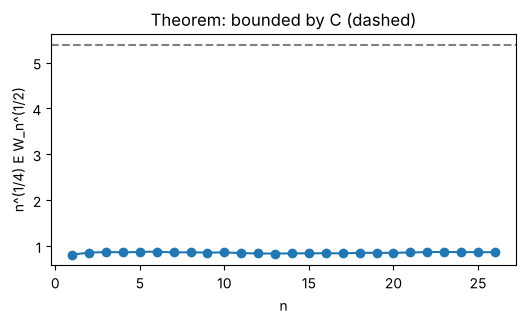

In [3]:
def run(n):
    H = 2 * n + 3; off = n + 1
    c = np.zeros(H, dtype=np.int64); c[off] = 1; M = 0
    out = []
    for k in range(1, n + 1):
        up = rng.poisson(c / (2 * math.e)); down = rng.poisson(c * math.e / 2)
        c = np.zeros(H, dtype=np.int64); c[1:] += up[:-1]; c[:-1] += down[1:]
        occupied = np.nonzero(c)[0]
        if occupied.size: M = max(M, occupied.max() - off)
        h = np.arange(H) - off
        out.append((float((c * np.exp(h)).sum()), M))
    return out
n, runs = 26, 4000
W = np.zeros((runs, n)); Mx = np.zeros((runs, n), dtype=int)
for r in range(runs):
    o = run(n); W[r] = [a for a, _ in o]; Mx[r] = [b for _, b in o]
ks = np.arange(1, n + 1)
print('E W_n at n=5,15,26:', W[:, 4].mean().round(3), W[:, 14].mean().round(3), W[:, 25].mean().round(3), '(true value 1, but heavy-tailed)')
half = np.sqrt(W).mean(axis=0)
print('n^(1/4) E[W_n^(1/2)] at n = 2, 6, 10, ..., 26:', (ks**0.25 * half)[1::4].round(3))
for L in (1, 2, 3, 4):
    print(f'P(M_26 >= {L}) = {np.mean(Mx[:, -1] >= L):.4f}  <=  e^-{L} = {math.exp(-L):.4f}')
plt.figure(figsize=(6, 3)); plt.plot(ks, ks**0.25 * half, 'o-'); plt.axhline(Cst, ls='--', color='grey')
plt.xlabel('n'); plt.ylabel('n^(1/4) E W_n^(1/2)'); plt.title('Theorem: bounded by C (dashed)'); plt.show()

The empirical mean of $W_n$ is unreliable for large $n$: the mean is carried by rare trees with a high individual, which a few thousand samples rarely see (the same phenomenon as Figure 5.2 of Volume 14 for the fourth moment). The half moment is stable, and $n^{1/4}\mathbb E[W_n^{1/2}]$ levels off, well below the constant $C$ of the theorem: the order $n^{-1/4}$ is right (Remark 6.3), the constant is not optimised. The maximum is as rare as Lemma 6.4 says.

**P6.3.**

In [4]:
ch = math.cosh(1)
for k in range(1, 7):
    exact = 1 + ch * (ch**k - 1) / (ch - 1)
    print(k, 'simulated', (W[:, k-1]**2).mean().round(2), ' exact', round(exact, 2))

1 simulated 2.56  exact 2.54
2 simulated 5.2  exact 4.92
3 simulated 9.58  exact 8.6
4 simulated 11.2  exact 14.27
5 simulated 15.08  exact 23.02
6 simulated 21.63  exact 36.52


The agreement degrades with $n$ for the same reason as for the mean: $\mathbb EW_n^2$ is carried by ever rarer trees.

**P6.4.** A smallest-prime-factor sieve gives the factorisation of every $n\le x$; $f(n)=f(p)f(n/p)$ with $p$ the smallest prime factor, computed in increasing order of $n$.

In [5]:
X = 10**6
spf = np.zeros(X + 1, dtype=np.int64)
for p in range(2, X + 1):
    if spf[p] == 0:
        spf[p::p][spf[p::p] == 0] = p
primes = np.nonzero(spf == np.arange(X + 1))[0]; primes = primes[primes >= 2]
cof = np.arange(X + 1) // np.maximum(spf, 1)

A loop over $n$ would be slow ($10^6$ steps per sample). Since $\mathrm{cof}(n)\le n/2$, the angles can be filled in blocks whose cofactors are already known: $n\in(2^j,2^{j+1}]$ has cofactor $\le2^j$. That vectorises the recursion.

In [6]:
blocks = [(1 << j, min(X, (1 << (j + 1)))) for j in range(0, 20)]
def sample_angles():
    ang = np.zeros(X + 1)
    ang[primes] = rng.uniform(0, 2*np.pi, primes.size)
    for lo, hi in blocks:
        idx = np.arange(lo + 1, hi + 1)
        comp = idx[cof[idx] > 1]
        ang[comp] = ang[spf[comp]] + ang[cof[comp]]
    return ang
xs = np.array([10**3, 10**4, 10**5, 10**6])
vals = []
for _ in range(300):
    f = np.exp(1j * sample_angles()); f[0] = 0
    S = np.cumsum(f)
    vals.append(np.abs(S[xs]) / np.sqrt(xs))
vals = np.array(vals)
for x, m in zip(xs, vals.mean(axis=0)):
    print(f'x = {x:>8d}: E|S(x)|/sqrt(x) ~ {m:.3f}   (log log x)^(-1/4) = {math.log(math.log(x))**-0.25:.3f}   Gaussian value sqrt(pi)/2 = {math.sqrt(math.pi)/2:.3f}')

x =     1000: E|S(x)|/sqrt(x) ~ 0.766   (log log x)^(-1/4) = 0.848   Gaussian value sqrt(pi)/2 = 0.886
x =    10000: E|S(x)|/sqrt(x) ~ 0.760   (log log x)^(-1/4) = 0.819   Gaussian value sqrt(pi)/2 = 0.886
x =   100000: E|S(x)|/sqrt(x) ~ 0.698   (log log x)^(-1/4) = 0.800   Gaussian value sqrt(pi)/2 = 0.886
x =  1000000: E|S(x)|/sqrt(x) ~ 0.715   (log log x)^(-1/4) = 0.786   Gaussian value sqrt(pi)/2 = 0.886


The ratio $\mathbb E|S(x)|/\sqrt x$ sits clearly below the Gaussian value $\frac{\sqrt\pi}2\approx0.886$ (what a sum of independent unit vectors would give), and, within the noise of $300$ samples, decreases slowly as $x$ grows, consistent with Harper's $(\log\log x)^{-1/4}$ up to a constant. At this range $\log\log x$ moves from $1.9$ to $2.6$: the decay is real, but no computer will ever see it clearly, which is why it took a theorem.